# Fases 4 y 5 — Clase `regular`: de dos a tres clases de calidad

Los modelos se entrenaron con las dos clases de Kaggle (`buena` / `mala`). La tercera clase se obtiene con dos umbrales sobre un puntaje $p$ que crece con el deterioro. Especificación: `docs/TRASPASO.md` §4.3.

$$\hat y = \begin{cases} \text{buena} & p < t_1 \\ \text{regular} & t_1 \le p < t_2 \\ \text{mala} & p \ge t_2 \end{cases}$$

**Protocolo (fijado antes de ver las fotos propias)**
1. **Selección** con los recortes de `mixed_quality` etiquetados por el grupo. Se comparan varios puntajes (XGBoost, CNN, su promedio, con y sin calibración) con validación cruzada agrupada por imagen de origen: los recortes de una misma foto comparten luz y fondo, así que nunca se reparten entre entrenamiento y validación.
2. **Regla de decisión:** se elige el candidato con mayor F1-macro de tres clases en validación cruzada. Los umbrales finales se ajustan después con todos los recortes.
3. **Evaluación única** en las 45 fotos propias, que no intervienen en ninguna decisión: matriz de confusión 3×3, F1-macro y recall de `mala`, también por celular y por fruta.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, cv2, joblib, torch
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (confusion_matrix, f1_score, recall_score, roc_auc_score, cohen_kappa_score,
                             ConfusionMatrixDisplay)

from fruitq.config import FIGURES, MODELS, LABELS, PROCESSED, RAW_PROPIAS, SEGMENTADAS, QUALITY_CLASSES, SEED
from fruitq.io import read_image, read_image_max, resolve_path
from fruitq.data import read_annotations
from fruitq.features import extract_features
from fruitq.segmentation import fruit_on_uniform_background, largest_fruit
from fruitq.size import equivalent_diameter
from fruitq.cnn import SmallCNN, to_tensor
from fruitq.quality import KAGGLE_D_NORM, KAGGLE_SIDE, fit_three_thresholds, kaggle_view, logit, masked_tile, three_class

CLASES = QUALITY_CLASSES                      # buena, regular, mala (orden de deterioro)
COLOR = dict(zip(CLASES, ["#86b6ef", "#2a78d6", "#104281"]))   # rampa ordinal de un solo tono

sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
def savefig(name):
    plt.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight"); plt.savefig(FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

xgb = joblib.load(MODELS / "clasico_mejor.joblib")
ck = torch.load(MODELS / "cnn_lr1e-3_do0.5.pt")
cnn = SmallCNN(2, tuple(ck["widths"]), ck["dropout"]); cnn.load_state_dict(ck["state_dict"]); cnn.eval()

def p_xgb(feats):
    return xgb["modelo"].predict_proba(np.asarray(feats))[:, 1]

def p_cnn(tiles):
    with torch.no_grad():
        return torch.softmax(cnn(to_tensor(np.asarray(tiles))), 1)[:, 1].numpy()

## 1. Recortes etiquetados

- **Una etiqueta por recorte.** La aplicación de etiquetado reparte los recortes en partes (orden aleatorio fijo con semilla 42 y parte = orden mód 3). Cada recorte conserva la etiqueta de quien etiquetó su parte. Los recortes comunes de otra parte solo sirven para medir el acuerdo entre personas (κ, `docs/fases/07_etica_impactos.md`, E5); si el dueño de la parte aún no los etiquetó, se usa la etiqueta común.
- Se excluyen los recortes marcados como `descartar` (fruta mal segmentada, partida o con fondo).
- El grupo de validación cruzada es la imagen de origen (`segmentacion.csv`).

In [2]:
seg = pd.read_csv(SEGMENTADAS / "segmentacion.csv")
seg["recorte"] = seg.recorte.str.replace("\\", "/", regex=False)
orden = seg.sample(frac=1.0, random_state=SEED).reset_index(drop=True)          # mismo orden que app/etiquetar.py
parte = pd.Series(np.arange(len(orden)) % 3 + 1, index=orden.recorte)

filas = []
for f in sorted(LABELS.glob("recortes_*.csv")):
    df = pd.read_csv(f).drop_duplicates("recorte", keep="last")
    df["parte"] = df.recorte.map(parte)
    df["propio"] = df.parte == df.parte.mode()[0]      # la parte de cada persona es la que más etiquetó
    filas.append(df.assign(etiquetador=f.stem.replace("recortes_", "")))
todas = pd.concat(filas, ignore_index=True)
lab = (todas.sort_values("propio", ascending=False)       # primero la etiqueta del dueño de la parte
            .drop_duplicates("recorte", keep="first"))
lab = lab[lab.calidad.isin(CLASES)].merge(seg[["recorte", "origen"]], on="recorte", how="left").reset_index(drop=True)
assert lab.origen.notna().all()

resumen = pd.crosstab(lab.etiquetador, lab.calidad)[CLASES]
resumen["total"] = resumen.sum(axis=1); resumen.loc["total"] = resumen.sum(axis=0)
print(f"{len(lab)} recortes válidos de {lab.origen.nunique()} imágenes de origen")
resumen

362 recortes válidos de 280 imágenes de origen


calidad,buena,regular,mala,total
etiquetador,,,,
giuseppe,106,61,33,200
sebastian,82,51,29,162
total,188,112,62,362


## 2. Puntajes de deterioro en los recortes

Para cada recorte se calculan tres puntajes:
- **XGBoost:** $P(\text{mala} \mid x)$ con las 57 características, extraídas del recorte y su máscara a la resolución de la foto original (la misma cámara y resolución de 256 px que en el entrenamiento).
- **CNN:** la fruta con el fondo en negro, centrada y reducida a 128×128 (`masked_tile`, igual que en el entrenamiento).
- **Ensamble:** el promedio de los dos.

Los recortes son frutas pequeñas dentro de una foto con varias frutas: su diámetro mediano es el 20 % del lado menor de la imagen, frente al 44 % en las fotos de entrenamiento. Por eso se prueba también una variante **reescalada**, que amplía el recorte hasta que la fruta tenga el diámetro típico de entrenamiento antes de extraer las características.

In [3]:
def leer_mascara(ruta_recorte):
    data = np.fromfile(str(resolve_path(ruta_recorte.replace(".jpg", "_mask.png"))), np.uint8)
    return ((cv2.imdecode(data, cv2.IMREAD_GRAYSCALE) > 127) * 255).astype(np.uint8)

D_OBJ = KAGGLE_D_NORM * KAGGLE_SIDE          # diámetro típico de la fruta en las imágenes de entrenamiento (px)
f_nat, f_esc, tiles = [], [], []
for r in lab.itertuples():
    crop, mask = read_image(r.recorte), leer_mascara(r.recorte)
    f_nat.append(extract_features(crop, mask))
    s = D_OBJ / equivalent_diameter(float((mask > 0).sum()))
    c2 = cv2.resize(crop, None, fx=s, fy=s, interpolation=cv2.INTER_CUBIC if s > 1 else cv2.INTER_AREA)
    m2 = cv2.resize(mask, (c2.shape[1], c2.shape[0]), interpolation=cv2.INTER_NEAREST)
    f_esc.append(extract_features(c2, m2))
    tiles.append(masked_tile(crop, mask))

lab["p_xgb"], lab["p_xgb_esc"], lab["p_cnn"] = p_xgb(f_nat), p_xgb(f_esc), p_cnn(tiles)
lab["p_ens"] = (lab.p_xgb + lab.p_cnn) / 2
lab["p_ens_esc"] = (lab.p_xgb_esc + lab.p_cnn) / 2
y = lab.calidad.to_numpy(dtype=object)

PUNTAJES = {"XGBoost": "p_xgb", "CNN": "p_cnn", "Ensamble": "p_ens",
            "XGBoost (reescalado)": "p_xgb_esc", "Ensamble (reescalado)": "p_ens_esc"}
bm = y != "regular"
pd.DataFrame({n: {"AUC buena vs mala": roc_auc_score(y[bm] == "mala", lab[c][bm]),
                  "AUC buena vs no buena": roc_auc_score(y != "buena", lab[c]),
                  **{f"mediana {k}": lab.loc[y == k, c].median() for k in CLASES},
                  "fracción entre 0.2 y 0.8": lab[c].between(0.2, 0.8).mean()} for n, c in PUNTAJES.items()}).T.round(3)

,AUC buena vs mala,AUC buena vs no buena,mediana buena,mediana regular,mediana mala,fracción entre 0.2 y 0.8
XGBoost,0.894,0.822,0.011,0.458,0.971,0.188
CNN,0.898,0.814,0.081,0.409,0.781,0.337
Ensamble,0.917,0.839,0.056,0.481,0.847,0.285
XGBoost (reescalado),0.852,0.756,0.005,0.157,0.784,0.180
Ensamble (reescalado),0.885,0.797,0.054,0.313,0.802,0.279


- Los recortes `regular` caen **entre** los `buena` y los `mala` en todos los puntajes: el modelo binario ya ordena el deterioro, aunque nunca vio la clase intermedia.
- La variante reescalada separa peor. Ampliar un recorte pequeño lo suaviza, y eso cambia las características de nitidez y textura respecto de las imágenes de entrenamiento. Se descarta para las fases siguientes del análisis, pero se mantiene en la comparación.

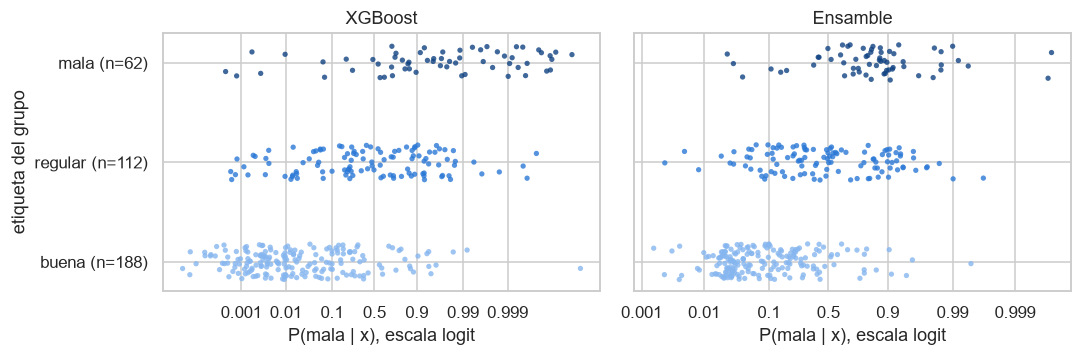

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
ticks = np.array([0.001, 0.01, 0.1, 0.5, 0.9, 0.99, 0.999])
rng = np.random.default_rng(SEED)
for ax, (nombre, col) in zip(axes, [("XGBoost", "p_xgb"), ("Ensamble", "p_ens")]):
    for i, k in enumerate(CLASES):
        v = logit(lab.loc[y == k, col])
        ax.scatter(v, i + rng.uniform(-0.18, 0.18, len(v)), s=12, color=COLOR[k], alpha=0.8, edgecolor="none")
    ax.set_xticks(logit(ticks)); ax.set_xticklabels([f"{t:g}" for t in ticks])
    ax.set_title(nombre); ax.set_xlabel("P(mala | x), escala logit")
axes[0].set_yticks(range(3)); axes[0].set_yticklabels([f"{k} (n={(y == k).sum()})" for k in CLASES])
axes[0].set_ylabel("etiqueta del grupo")
plt.tight_layout(); savefig("calidad_puntajes_recortes"); plt.show()

## 3. Selección del puntaje y de los umbrales (validación cruzada agrupada)

**Sobre la calibración.** XGBoost está sobreconfiado: sus probabilidades se concentran cerca de 0 y de 1. Calibrar con Platt (regresión logística sobre $\operatorname{logit} p$) o con regresión isotónica da probabilidades más fieles, **pero ninguna de las dos cambia el orden de los recortes**: Platt es estrictamente creciente, así que las particiones posibles con dos umbrales y el F1 alcanzable son idénticos; la isotónica es creciente por tramos y puede empatar recortes distintos, lo que solo puede quitar particiones. La rejilla de umbrales usa los cuantiles del propio puntaje, de modo que la concentración cerca de 0 y 1 tampoco la afecta. Se incluyen en la comparación para comprobarlo.

**Esquema.** `StratifiedGroupKFold` con 5 pliegues, agrupado por imagen de origen. En cada pliegue, la calibración (si la hay) y los umbrales se ajustan con los otros cuatro pliegues, y se predice el pliegue excluido.

In [5]:
def platt(p, yy):
    lr = LogisticRegression().fit(logit(p)[:, None], yy == "mala")
    return lambda q: lr.predict_proba(logit(q)[:, None])[:, 1]

def isotonica(p, yy):
    return IsotonicRegression(out_of_bounds="clip").fit(p, (yy == "mala").astype(float)).predict

CANDIDATOS = {"XGBoost": ("p_xgb", None), "XGBoost + Platt": ("p_xgb", platt), "XGBoost + isotónica": ("p_xgb", isotonica),
              "CNN": ("p_cnn", None), "Ensamble": ("p_ens", None), "Ensamble + Platt": ("p_ens", platt),
              "XGBoost (reescalado)": ("p_xgb_esc", None), "Ensamble (reescalado)": ("p_ens_esc", None)}
pliegues = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(lab, y, lab.origen))

def metricas(yy, pred):
    cm = confusion_matrix(yy, pred, labels=CLASES)
    return {"F1-macro": f1_score(yy, pred, labels=CLASES, average="macro", zero_division=0),
            "recall buena": cm[0, 0] / cm[0].sum(), "recall regular": cm[1, 1] / cm[1].sum(), "recall mala": cm[2, 2] / cm[2].sum(),
            "mala → buena": cm[2, 0] / cm[2].sum(),
            "κ ponderado": cohen_kappa_score(yy, pred, labels=CLASES, weights="linear")}

filas, pred_cv = [], {}
for nombre, (col, cal) in CANDIDATOS.items():
    pred, f1s = np.empty(len(y), dtype=object), []
    for tr, te in pliegues:
        ptr, pte = lab[col].to_numpy()[tr], lab[col].to_numpy()[te]
        if cal is not None:
            g = cal(ptr, y[tr]); ptr, pte = g(ptr), g(pte)
        t1, t2, _ = fit_three_thresholds(ptr, y[tr])
        pred[te] = three_class(pte, t1, t2)
        f1s.append(f1_score(y[te], pred[te], labels=CLASES, average="macro"))
    pred_cv[nombre] = pred
    filas.append({"candidato": nombre, **metricas(y, pred), "desv. F1 entre pliegues": np.std(f1s)})
cv_tabla = pd.DataFrame(filas).set_index("candidato")
cv_tabla.round(3).to_csv(ROOT / "reports" / "tabla_tres_clases_cv.csv")
ELEGIDO = cv_tabla["F1-macro"].idxmax()          # regla de decisión fijada de antemano
print("Candidato elegido:", ELEGIDO)
cv_tabla.round(3)

Candidato elegido: XGBoost


,F1-macro,recall buena,recall regular,recall mala,mala → buena,κ ponderado,desv. F1 entre pliegues
candidato,,,,,,,
XGBoost,0.623,0.787,0.607,0.435,0.113,0.520,0.102
XGBoost + Platt,0.623,0.787,0.607,0.435,0.113,0.520,0.102
XGBoost + isotónica,0.611,0.761,0.580,0.452,0.145,0.490,0.076
CNN,0.533,0.686,0.330,0.661,0.081,0.438,0.035
Ensamble,0.578,0.729,0.321,0.823,0.097,0.495,0.059
Ensamble + Platt,0.578,0.729,0.321,0.823,0.097,0.495,0.059
XGBoost (reescalado),0.488,0.681,0.304,0.500,0.161,0.342,0.057
Ensamble (reescalado),0.513,0.707,0.321,0.532,0.097,0.404,0.048


**Lectura de la tabla**
- La regla de decisión (mayor F1-macro en validación cruzada) se aplica en el código, antes de calcular cualquier resultado en las fotos propias.
- Platt da exactamente el mismo resultado que el puntaje sin calibrar, como se anticipó; la isotónica, un poco menos.
- La columna **mala → buena** es el error más costoso (fruta dañada que se aprueba). Hay que leerla junto con el F1: un candidato puede ganar en F1 enviando más fruta mala a `regular`, que es un error menos grave que aprobarla como buena.
- Como referencia del techo alcanzable, el acuerdo entre dos personas del grupo fue κ ponderado = 0.83 (E5).

In [6]:
col_elegido = CANDIDATOS[ELEGIDO][0]
p_all = lab[col_elegido].to_numpy()
# Los umbrales se fijan sobre el puntaje sin calibrar (Platt no cambia el orden); la calibración
# solo se usa para mostrar en la aplicación una probabilidad interpretable.
calibrador = platt(p_all, y)
T1, T2, F1_AJUSTE = fit_three_thresholds(p_all, y)
print(f"Umbrales finales ({ELEGIDO}, ajustados con los {len(y)} recortes): t1 = {T1:.4f}, t2 = {T2:.4f} | F1-macro de ajuste = {F1_AJUSTE:.3f}")
reparto = pd.Series(three_class(p_all, T1, T2)).value_counts().reindex(CLASES)
print("Reparto de los recortes con estos umbrales:", reparto.to_dict())

Umbrales finales (XGBoost, ajustados con los 362 recortes): t1 = 0.1654, t2 = 0.9851 | F1-macro de ajuste = 0.639


Reparto de los recortes con estos umbrales: {'buena': 188, 'regular': 137, 'mala': 37}


## 4. Evaluación única en las fotos propias

Preparación (`docs/TRASPASO.md` §4.3, paso 5), para que la fruta tenga la escala de las imágenes de entrenamiento:
1. lectura con `read_image_max(ruta, 1024)` y segmentación con `fruit_on_uniform_background` (si falla, `largest_fruit`);
2. `kaggle_view`: cuadrado centrado en la fruta de lado $d / 0.436$, reducido a 256 px; así la fruta ocupa la misma fracción de la imagen que la mediana de Kaggle en train;
3. las 57 características y la entrada de la CNN se calculan sobre ese recorte.

Esta celda es la única que usa las fotos propias, y lo hace con el candidato y los umbrales ya fijados.

In [7]:
anot = read_annotations(LABELS / "anotaciones_propias.csv")
anot = anot[anot.conjunto == "principal"].reset_index(drop=True)
celular = pd.read_csv(ROOT / "reports" / "tabla_tamano_fotos_propias.csv").set_index("archivo").celular

feats, tiles_p, fallback = [], [], []
for r in anot.itertuples():
    img = read_image_max(RAW_PROPIAS / r.archivo, 1024)
    reg = fruit_on_uniform_background(img)
    fallback.append(reg is None)
    if reg is None:
        reg = largest_fruit(img)
    crop, mask = kaggle_view(img, reg.contour)
    feats.append(extract_features(crop, mask)); tiles_p.append(masked_tile(crop, mask))

prop = anot[["archivo", "id_fruta", "fruta", "calidad"]].copy()
prop["celular"] = prop.archivo.map(celular).fillna("sin metadatos")
prop["p_xgb"], prop["p_cnn"] = p_xgb(feats), p_cnn(tiles_p)
prop["p_ens"] = (prop.p_xgb + prop.p_cnn) / 2
prop["p_mala_calibrada"] = calibrador(prop[col_elegido].to_numpy())
prop["prediccion"] = three_class(prop[col_elegido], T1, T2)
yp = prop.calidad.to_numpy(dtype=object)
print(f"Fotos: {len(prop)} | sin fondo uniforme detectado: {sum(fallback)}")
res = metricas(yp, prop.prediccion.to_numpy(dtype=object))
pd.Series(res).round(3)

Fotos: 45 | sin fondo uniforme detectado: 0


F1-macro          0.253
recall buena      0.200
recall regular    0.267
recall mala       0.267
mala → buena      0.000
κ ponderado      -0.053
dtype: float64

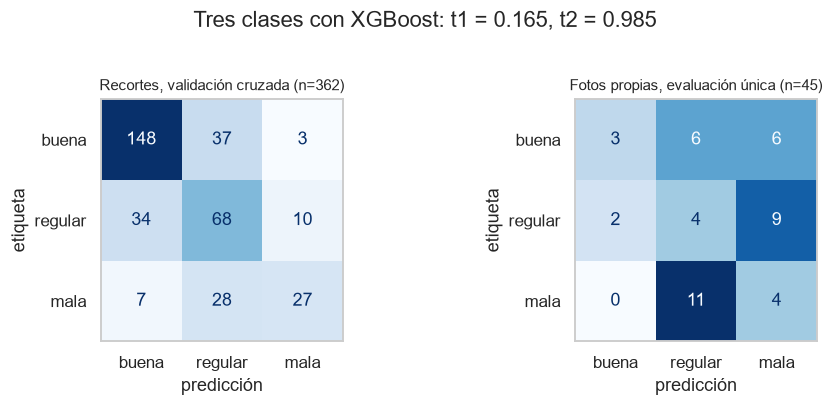

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (titulo, yy, pp) in zip(axes, [(f"Recortes, validación cruzada (n={len(y)})", y, pred_cv[ELEGIDO]),
                                        (f"Fotos propias, evaluación única (n={len(yp)})", yp, prop.prediccion.to_numpy(dtype=object))]):
    ConfusionMatrixDisplay(confusion_matrix(yy, pp, labels=CLASES), display_labels=CLASES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.grid(False); ax.set_title(titulo, fontsize=10); ax.set_xlabel("predicción"); ax.set_ylabel("etiqueta")
plt.suptitle(f"Tres clases con {ELEGIDO}: t1 = {T1:.3f}, t2 = {T2:.3f}", y=1.02)
plt.tight_layout(); savefig("calidad_confusion"); plt.show()

### Por fruta y por celular

Cada combinación fruta × calidad se fotografió en una sola sesión, con un solo celular (`docs/TRASPASO.md` §4.1). Por eso el desglose por celular **no separa** el efecto de la cámara del efecto de la calidad: se reporta como descripción, no como prueba causal.

In [9]:
def resumen_grupo(d):
    yy, pp = d.calidad.to_numpy(dtype=object), d.prediccion.to_numpy(dtype=object)
    return pd.Series({"fotos": len(d), "exactitud": (yy == pp).mean(),
                      "F1-macro": f1_score(yy, pp, labels=CLASES, average="macro", zero_division=0),
                      "mala → buena": int(((yy == "mala") & (pp == "buena")).sum())})
por_fruta = prop.groupby("fruta").apply(resumen_grupo)
por_celular = prop.groupby("celular").apply(resumen_grupo)
display(por_fruta.round(3)); display(por_celular.round(3))
pd.crosstab([prop.fruta, prop.calidad], prop.prediccion).reindex(columns=CLASES, fill_value=0)

,fotos,exactitud,F1-macro,mala → buena
fruta,,,,
banano,15.0,0.000,0.000,0.0
guayaba,15.0,0.200,0.225,0.0
manzana,15.0,0.533,0.537,0.0


,fotos,exactitud,F1-macro,mala → buena
celular,,,,
iPhone 13,20.0,0.2,0.193,0.0
moto g(9) play,20.0,0.2,0.111,0.0
sin metadatos,5.0,0.6,0.250,0.0


prediccion       buena  regular  mala
fruta   calidad                      
banano  buena        0        0     5
        mala         0        5     0
        regular      0        0     5
guayaba buena        1        4     0
        mala         0        4     1
        regular      0        1     4
manzana buena        2        2     1
        mala         0        2     3
        regular      2        3     0

**Referencia binaria.** Sin la clase intermedia (solo las fotos `buena` y `mala`, con el umbral 0.5 del modelo binario), se mide si el problema está en los umbrales de `regular` o en la generalización del modelo a fotos nuevas.

In [10]:
bin_ = prop[prop.calidad != "regular"]
yb = (bin_.calidad == "mala").to_numpy()
pd.DataFrame({n: {"exactitud con umbral 0.5": ((bin_[c] >= 0.5).to_numpy() == yb).mean(),
                  "AUC": roc_auc_score(yb, bin_[c])} for n, c in [("XGBoost", "p_xgb"), ("CNN", "p_cnn"), ("Ensamble", "p_ens")]}).T.round(3)

,exactitud con umbral 0.5,AUC
XGBoost,0.667,0.547
CNN,0.433,0.453
Ensamble,0.500,0.533


## 5. Análisis de errores en las fotos propias

Este análisis busca la causa del resultado anterior. No modifica el modelo, el candidato ni los umbrales: cualquier corrección que sugiera debe validarse con fotos nuevas, porque estas 45 ya se usaron para evaluar.

Primero se revisa que la preparación sea correcta: una foto de cada fruta y calidad, tal como la recibe el modelo.

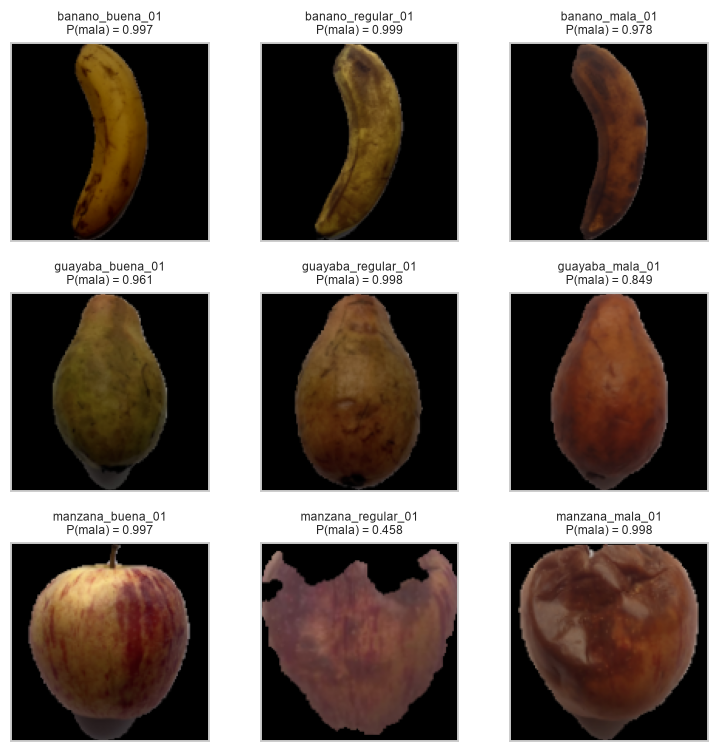

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(7, 7))
for i, fr in enumerate(["banano", "guayaba", "manzana"]):
    for j, k in enumerate(CLASES):
        idx = prop.index[(prop.fruta == fr) & (prop.calidad == k)][0]
        ax = axes[i, j]; ax.imshow(tiles_p[idx]); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(f"{prop.archivo[idx][:-4]}\nP(mala) = {prop.p_xgb[idx]:.3f}", fontsize=8)
plt.tight_layout(); savefig("calidad_fotos_propias_entrada"); plt.show()

Luego se comparan las características de las fotos propias con las del train de Kaggle para las mismas frutas: brillo (V de HSV y L de Lab), saturación y las dos características de nitidez.

In [12]:
NOMBRES = list(xgb["features"])
fp = pd.DataFrame(np.asarray(feats, dtype=float), columns=NOMBRES).assign(fruta=prop.fruta, calidad=prop.calidad)
kg = pd.read_parquet(PROCESSED / "features.parquet")
kg = kg[(kg.split == "train") & kg.seg_ok & kg.fruta.isin(["banano", "guayaba", "manzana"])]
COLS = ["hsv_v_mean", "lab_l_mean", "hsv_s_mean", "laplacian_var", "gradient_energy", "dark_frac"]
comp = pd.concat({"Kaggle (train)": kg.groupby(["fruta", "calidad"])[COLS].median(),
                  "fotos propias": fp.groupby(["fruta", "calidad"])[COLS].median()}, names=["fuente"])
comp.round(2)

hsv_v_mean  lab_l_mean  hsv_s_mean  \
fuente         fruta   calidad                                       
Kaggle (train) banano  buena        178.78      172.12      115.49   
                       mala         114.14       96.85      119.60   
               guayaba buena        136.02      130.18      136.51   
                       mala         146.92      130.95      122.12   
               manzana buena        156.17      133.25      152.52   
                       mala         168.10      122.58      139.94   
fotos propias  banano  buena         97.92       73.86      238.22   
                       mala          82.76       60.10      152.40   
                       regular      117.49      101.31      176.44   
               guayaba buena         78.23       70.23      165.03   
                       mala          96.32       67.49      161.28   
                       regular       86.61       68.83      156.35   
               manzana buena         99.83       81.54      160.12   
                       mala          92.88       69.49      148.23   
                       regular      100.56       82.42       88.17   

                                laplacian_var  gradient_energy  dark_frac  
fuente         fruta   calidad                                             
Kaggle (train) banano  buena           450.89            65.67       0.05  
                       mala            995.43            93.56       0.18  
               guayaba buena           944.45            68.51       0.09  
                       mala            260.79            55.78       0.05  
               manzana buena           173.36            39.12       0.01  
                       mala            218.33            49.10       0.02  
fotos propias  banano  buena            89.14            30.19       0.10  
                       mala             22.30            19.66       0.16  
                       regular         158.19            45.34       0.09  
               guayaba buena            64.42            25.11       0.31  
                       mala             35.91            21.18       0.15  
                       regular          90.02            29.77       0.20  
               manzana buena           315.14            40.52       0.19  
                       mala            140.28            35.51       0.08  
                       regular          47.35            22.81       0.00

**Prueba del atajo de nitidez.** En la fase 4, la ablación mostró que la nitidez (`laplacian_var`, `gradient_energy`) es lo que más usa XGBoost, pero que su relación con la calidad cambia de signo según la fruta, lo que sugería un atajo de la cámara. Si es un atajo, en fotos de otra cámara debería desordenar las predicciones. Para comprobarlo, se reemplaza la nitidez de cada foto propia por la mediana de Kaggle de su fruta, se deja todo lo demás igual y se mide si el modelo vuelve a ordenar bien las fotos `buena` y `mala` (AUC).

In [13]:
fp2 = fp.copy()
for fr in ["banano", "guayaba", "manzana"]:
    for c in ["laplacian_var", "gradient_energy"]:
        fp2.loc[fp2.fruta == fr, c] = kg.loc[kg.fruta == fr, c].median()
p_sin_nitidez = p_xgb(fp2[NOMBRES].to_numpy())
m = (prop.calidad != "regular").to_numpy()
yb2 = (prop.calidad[m] == "mala").to_numpy()
pd.DataFrame({"AUC buena vs mala": [roc_auc_score(yb2, prop.p_xgb[m]), roc_auc_score(yb2, p_sin_nitidez[m])],
              "mediana P(mala) en fotos buena": [prop.p_xgb[prop.calidad == "buena"].median(),
                                                 np.median(p_sin_nitidez[(prop.calidad == "buena").to_numpy()])]},
             index=["características originales", "nitidez reemplazada por la mediana de Kaggle"]).round(3)

,AUC buena vs mala,mediana P(mala) en fotos buena
características originales,0.547,0.956
nitidez reemplazada por la mediana de Kaggle,0.907,0.988


**Conclusiones del análisis de errores**
1. **La preparación funciona:** las 45 frutas se segmentan sobre el fondo uniforme y llegan al modelo centradas y a la escala de entrenamiento. La excepción son las fotos comprimidas de `manzana_regular`, cuya máscara queda irregular.
2. **Atajo de nitidez confirmado.** Las fotos propias tienen una nitidez muy distinta a la de Kaggle, y con ella el modelo ordena las fotos casi al azar (AUC ≈ 0.55). Al neutralizar solo la nitidez, el orden se recupera (AUC ≈ 0.91). Por tanto, el modelo usa la nitidez como indicador de la cámara o la sesión de cada carpeta de Kaggle, no como indicador del defecto.
3. **Segundo cambio de dominio: brillo y madurez.** Aun sin el atajo, casi todas las fotos reciben P(mala) cercana a 1. Las fotos propias son mucho más oscuras: V entre 78 y 118 frente a 114–179 en Kaggle, probablemente porque la exposición automática del celular compensa el fondo blanco. Además, la fruta `buena` del grupo es fruta madura de mercado colombiano (banano con pecas, guayaba amarillenta), mientras que la `buena` de Kaggle es fruta más verde y uniforme.
4. **Consecuencia:** los umbrales de `regular` funcionan en la distribución donde se eligieron (recortes de Kaggle), pero el sistema completo no generaliza a fotos nuevas. Para usarlo con fruta local se necesita: (a) reentrenar sin las características de nitidez; (b) normalizar el brillo con el fondo blanco como referencia; (c) incluir fotos propias en el entrenamiento. Cada cambio debe validarse con fotos nuevas, no con estas 45.

## 6. Parámetros para la aplicación

Se guardan en `models/umbrales.json`, sección `calidad`, sin modificar la sección `tamano`. La aplicación calcula el puntaje del candidato elegido, asigna la clase con $t_1, t_2$ y muestra la probabilidad calibrada con Platt (coeficientes `platt`: $P = \sigma(a \cdot \operatorname{logit} p + b)$). La tabla por foto queda en `reports/tabla_calidad_fotos_propias.csv`.

In [14]:
lr_platt = LogisticRegression().fit(logit(p_all)[:, None], y == "mala")      # mismo ajuste que `calibrador`
ruta = MODELS / "umbrales.json"
params = json.loads(ruta.read_text(encoding="utf-8")) if ruta.exists() else {}
params["calidad"] = {
    "descripcion": "clase = buena si p < t1, regular si t1 <= p < t2, mala si p >= t2",
    "puntaje": ELEGIDO,
    "columna": col_elegido,
    "preparacion": f"kaggle_view: cuadrado de lado d / {KAGGLE_D_NORM} reducido a {KAGGLE_SIDE} px",
    "t1": round(T1, 6), "t2": round(T2, 6),
    "clases": CLASES,
    "platt": {"a": round(float(lr_platt.coef_[0, 0]), 6), "b": round(float(lr_platt.intercept_[0]), 6)},
    "seleccion": {"recortes": int(len(y)), "esquema": "StratifiedGroupKFold(5) por imagen de origen",
                  **{k: round(float(v), 3) for k, v in cv_tabla.loc[ELEGIDO].items()}},
    "fotos_propias": {"fotos": int(len(prop)), **{k: round(float(v), 3) for k, v in res.items()}},
    "advertencia": "Validado en recortes de Kaggle; no generaliza a las fotos propias (docs/fases/05_evaluacion.md)",
}
ruta.write_text(json.dumps(params, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
prop.round(4).to_csv(ROOT / "reports" / "tabla_calidad_fotos_propias.csv", index=False)
print(json.dumps(params["calidad"], indent=2, ensure_ascii=False))

{
  "descripcion": "clase = buena si p < t1, regular si t1 <= p < t2, mala si p >= t2",
  "puntaje": "XGBoost",
  "columna": "p_xgb",
  "preparacion": "kaggle_view: cuadrado de lado d / 0.436 reducido a 256 px",
  "t1": 0.165359,
  "t2": 0.9851,
  "clases": [
    "buena",
    "regular",
    "mala"
  ],
  "platt": {
    "a": 0.348282,
    "b": -1.693997
  },
  "seleccion": {
    "recortes": 362,
    "esquema": "StratifiedGroupKFold(5) por imagen de origen",
    "F1-macro": 0.623,
    "recall buena": 0.787,
    "recall regular": 0.607,
    "recall mala": 0.435,
    "mala → buena": 0.113,
    "κ ponderado": 0.52,
    "desv. F1 entre pliegues": 0.102
  },
  "fotos_propias": {
    "fotos": 45,
    "F1-macro": 0.253,
    "recall buena": 0.2,
    "recall regular": 0.267,
    "recall mala": 0.267,
    "mala → buena": 0.0,
    "κ ponderado": -0.053
  },
  "advertencia": "Validado en recortes de Kaggle; no generaliza a las fotos propias (docs/fases/05_evaluacion.md)"
}
